In [1]:
from em1d.inversion import *
from em1d.experiment import *

def parse_line(f):
    line = str(f.readline())
    if '!' in line:
        line = line[:line.index('!')]
    line = line.strip()
    if '\t' in line:
        res = line.split('\t')
        res = [x for x in res if x != '']
    elif ' ' in line:
        res = line.split(' ')
        res = [x for x in res if x != '']
    else:
        res = [line]
    if isinstance(res, list):
        res = [float(x) for x in res]
    return res

In [8]:
import numpy as np
with open("P:/matt.griffiths/20230119.tem", 'r') as f:
    data_entries = f.readline().split(';')
    data_header = {}
    for i, item in enumerate(data_entries):
        param, value = item.split('=')
        try:
            data_header[param] = float(value)
        except:
            data_header[param] = value
    _ = parse_line(f) # source type stuff
    txrx_pos = parse_line(f)
    n_seg,area = parse_line(f)
    x,y,z = [],[],[]
    for i in range(int(n_seg)):
        x_,y_ = parse_line(f)
        x.append(x_)
        y.append(y_)
        z.append(float(txrx_pos[2]))
    x.append(x[0])
    y.append(y[0])
    z.append(z[0])
    src = Loop(x,y, z)
    rx = Receiver(*txrx_pos[3:])

    assert all(x==3. for x in parse_line(f)), 'other data types not supported, must by in db/dt'
    wv_type,n_wv = parse_line(f)
    if wv_type==3.:
        wvs = []
        for i in range(int(n_wv)):
            wv_ = np.array(parse_line(f)[1:])
            wvs.append(Waveform( wv_[::4], wv_[2::4]))       
    if n_wv==1:
        wvs = wvs[0]
    n_filt,frontgate,frontgate_scale = parse_line(f)
    filters = []
    for i in range(int(n_filt)):
        ncut,forder,fcut = parse_line(f)
        forder = int(round(forder))
        filters.append(ButterworthFilter(fcut, forder))
        _ = parse_line(f)
    if frontgate==1:
        (fgate_time) = parse_line(f)
    for i in range(int(n_filt)):
        ncut,forder,fcut = parse_line(f)
        filters.append(ButterworthFilter(fcut, forder))
        _ = parse_line(f)
    
    data = np.fromstring(f.read(), sep=' ')
    if len(data)%5==0:
        data = data.reshape(-1,5).T
    elif len(data)%7==0:
        data = data.reshape(-1,7).T
        t_start = data[5]
        t_end   = data[6]

    t_center = torch.from_numpy(data[0]).to(torch.double)
    data_obs = torch.from_numpy(data[1]).to(torch.double)
    relerr   = torch.from_numpy(data[2]).to(torch.double)
    data_err = data_obs*relerr

    filters = FilterChain(filters)
    if n_wv==1:
        fwr = Forward(src, rx, t_center, waveform=wvs, filterfunc=filters, tolerance=1e-5)

    model = SmoothModel.starting_model(51)
    inv = Inversion(data_obs, data_err, model, fwr)
    res_mod = inv.invert(smoothness=1e2)


\\bubi4.uni.au.dk\people\matt.griffiths\_git\em1d\src\em1d\experiment\experiment.py:109: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return tc.tensor(overall_min)


001	misfit:	51.12
002	misfit:	10.10
increased max step
003	misfit:	8.72
increased max step
004	misfit:	3.54
increased max step
005	misfit:	2.60
increased max step
006	misfit:	1.35
increased max step
007	misfit:	0.95
increased max step
008	misfit:	0.93
increased max step
009	misfit:	0.93
misfit change is less than 1e-3

 9


In [9]:
rho_mod = res_mod.copy()
rho_mod.values = [1/rho_mod.values[0]]

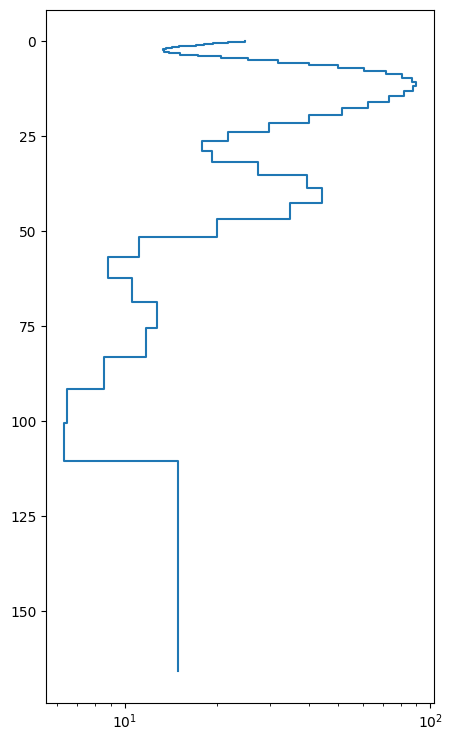

In [10]:
import matplotlib.pyplot as plt
import numpy as np

fig,ax=plt.subplots(figsize=(5,9))
ax = rho_mod.plot(ax=ax)
ax.set_ylim(ax.get_ylim()[::-1])
ax.set_xscale('log')